In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input

In [2]:
data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\AutoEncoder\CreditCard\creditcard.csv')

In [3]:
print(data.head())
print(data.shape)

print(data['Class'].value_counts())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
X = data.drop('Class', axis=1).values
y = data['Class'].values

In [5]:
X_train, X_test, y_train,y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
X_train_normal = X_train[y_train==0]

X_train_normal, X_val_normal = train_test_split(
    X_train_normal, test_size=0.1, random_state=42
)

scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_val_normal = scaler.transform(X_val_normal)
X_test = scaler.transform(X_test)

print("Training data:", X_train_normal.shape)
print("Testing data:", X_test.shape)

Training data: (204705, 30)
Testing data: (56962, 30)


In [8]:
input_layer = Input(shape=(30,))

encoded = Dense(16, activation='relu')(input_layer)
encoded = Dense(8, activation='relu')(encoded)

decoded = Dense(16, activation='relu')(encoded)
decoded = Dense(30, activation='linear')(decoded)

model = Model(input_layer, decoded)

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    X_train_normal, X_train_normal, 
    epochs=10, 
    batch_size=256,
    validation_data=(X_val_normal, X_val_normal)
)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.7884 - mae: 0.5965 - val_loss: 0.6255 - val_mae: 0.5428
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.6051 - mae: 0.5268 - val_loss: 0.5692 - val_mae: 0.5152
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.5710 - mae: 0.5106 - val_loss: 0.5483 - val_mae: 0.5041
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.5497 - mae: 0.5004 - val_loss: 0.5303 - val_mae: 0.4952
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.5302 - mae: 0.4900 - val_loss: 0.5166 - val_mae: 0.4869
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.5178 - mae: 0.4833 - val_loss: 0.5056 - val_mae: 0.4795
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5101 - mae: 0.4777 - val_loss: 0.5013 - val_mae: 0.4749
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5051 - mae: 0.4732 - val_loss: 0.4970 - val_mae: 0.4709
Epoch 9/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - lo

In [11]:
val_predictions = model.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_predictions), axis=1
)

threshold = np.percentile(val_errors, 99)

print("Threshold: ", threshold)

711/711 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Threshold:  2.879647795584708


In [12]:
test_predictions = model.predict(X_test)

test_errors = np.mean(
    np.square(X_test - test_predictions), axis=1
)

y_pred = (test_errors > threshold).astype(int)

print("Confusion Matrix: ")
print(confusion_matrix(y_test, y_pred))

print("Classification Report: ")
print(classification_report(y_test, y_pred, zero_division=0))

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Confusion Matrix: 
[[56268   596]
 [   18    80]]
Classification Report: 
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.82      0.21        98

    accuracy                           0.99     56962
   macro avg       0.56      0.90      0.60     56962
weighted avg       1.00      0.99      0.99     56962



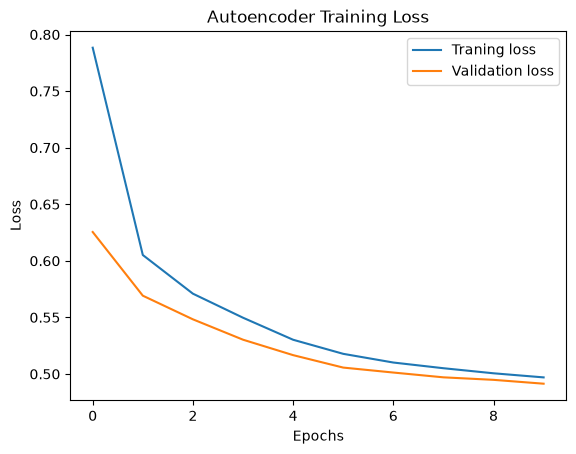

In [13]:
plt.plot(history.history['loss'], label='Traning loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [14]:
print("\nPredicted Fraud Transactions:", sum(y_pred))
print("Actual Fraud Transactions:", sum(y_test))


Predicted Fraud Transactions: 676
Actual Fraud Transactions: 98
